<a href="https://colab.research.google.com/github/Nayan-135/DWBI_Lab_Project/blob/main/DWBI_Lab_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IT-3 DWBI Lab Project
### Topic :- Apache Spark
##### Name :-
#####         1) Hrishi Khapaker (37)
#####         2) Nayan Ghate (45)
#####         3) Shivanshu Barapatre(54)

In [ ]:
# ============================================================
# PART 1: SETUP
# Spark component: SparkSession (entry point to all Spark features)
# ============================================================
!pip install -q pyspark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
    .appName("NYC_Taxi_Analytics")
    .config("spark.driver.memory", "6g")            # memory for the driver (Colab has ~12 GB)
    .config("spark.sql.shuffle.partitions", "32")   # fewer shuffle partitions = faster on a small machine
    .getOrCreate())

print("Spark version:", spark.version)

Spark version: 4.0.4


In [ ]:
# ============================================================
# PART 2: DOWNLOAD DATA
# NYC Yellow Taxi trip data in Parquet format (3 months of 2024)
# If a link fails, get the current link from the NYC TLC
# "Trip Record Data" page.
# ============================================================
months = ["2024-01", "2024-02", "2024-03"]

for m in months:
    !wget -q -nc https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{m}.parquet

!ls -lh *.parquet   # check that the files downloaded

-rw-r--r-- 1 root root 48M Mar 21  2024 yellow_tripdata_2024-01.parquet
-rw-r--r-- 1 root root 49M Apr 19  2024 yellow_tripdata_2024-02.parquet
-rw-r--r-- 1 root root 58M May 22  2024 yellow_tripdata_2024-03.parquet


In [ ]:
# ============================================================
# PART 3: LOAD DATA
# Spark component: Data Source API (reading Parquet files)
# Each month is read separately, only the needed columns are
# kept, and types are fixed so the files can be merged safely.
# ============================================================
cols = {
    "tpep_pickup_datetime":  "timestamp",
    "tpep_dropoff_datetime": "timestamp",
    "passenger_count":       "int",
    "trip_distance":         "double",
    "PULocationID":          "int",
    "DOLocationID":          "int",
    "payment_type":          "int",
    "fare_amount":           "double",
    "tip_amount":            "double",
    "total_amount":          "double",
}

df = None
for m in months:
    part = spark.read.parquet(f"yellow_tripdata_{m}.parquet")
    part = part.select([F.col(c).cast(t).alias(c) for c, t in cols.items()])
    df = part if df is None else df.unionByName(part)   # merge months by column name

print("Raw rows:", df.count())   # ACTION: triggers the actual read
df.printSchema()
df.show(5)

Raw rows: 9554778
root
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- total_amount: double (nullable = true)

+--------------------+---------------------+---------------+-------------+------------+------------+------------+-----------+----------+------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|PULocationID|DOLocationID|payment_type|fare_amount|tip_amount|total_amount|
+--------------------+---------------------+---------------+-------------+------------+------------+------------+-----------+----------+------------+
| 2024-01-01 00:57:55|  2024-01-01 01:17:43|              

In [ ]:
# ============================================================
# PART 4: CLEANING + FEATURE ENGINEERING
# Spark component: DataFrame API transformations (lazy)
# Nothing runs until an action like count() is called.
# ============================================================
clean = (df
    # remove invalid or extreme values
    .filter((F.col("fare_amount") > 0) & (F.col("fare_amount") < 200))
    .filter((F.col("trip_distance") > 0) & (F.col("trip_distance") < 100))
    .filter(F.col("passenger_count") > 0)

    # new columns derived from the pickup time
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_dow",  F.dayofweek("tpep_pickup_datetime"))   # 1 = Sunday
    .withColumn("pickup_month", F.month("tpep_pickup_datetime"))

    # trip duration in minutes
    .withColumn("duration_min",
        (F.unix_timestamp("tpep_dropoff_datetime") -
         F.unix_timestamp("tpep_pickup_datetime")) / 60)
    .filter((F.col("duration_min") > 1) & (F.col("duration_min") < 180))

    # keep only trips that fall in the 3 months we loaded
    .filter(F.col("pickup_month").isin(1, 2, 3))
)

# Cache: store the cleaned data in memory so later steps are faster
clean.cache()
print("Clean rows:", clean.count())   # ACTION: also fills the cache

# Register as a SQL table so we can query it with Spark SQL
clean.createOrReplaceTempView("trips")

Clean rows: 8444455


In [ ]:
# ============================================================
# PART 5: ANALYTICS
# Spark component: Spark SQL (SQL on distributed data)
# GROUP BY causes a shuffle across partitions.
# ============================================================

# --- Insight 1: trips and average fare by hour of day ---
print("Trips and average fare by hour")
spark.sql("""
    SELECT pickup_hour,
           COUNT(*)                  AS trips,
           ROUND(AVG(fare_amount),2) AS avg_fare
    FROM trips
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""").show(24)

# --- Insight 2: top 10 busiest pickup zones ---
print("Top 10 pickup zones")
spark.sql("""
    SELECT PULocationID, COUNT(*) AS trips
    FROM trips
    GROUP BY PULocationID
    ORDER BY trips DESC
    LIMIT 10
""").show()

# --- Insight 3: busiest day of week ---
print("Trips by day of week (1=Sunday ... 7=Saturday)")
spark.sql("""
    SELECT pickup_dow, COUNT(*) AS trips, ROUND(AVG(fare_amount),2) AS avg_fare
    FROM trips
    GROUP BY pickup_dow
    ORDER BY pickup_dow
""").show()

# --- Insight 4: WINDOW FUNCTION, top 3 zones for every hour ---
print("Top 3 zones for each hour")
spark.sql("""
    SELECT * FROM (
        SELECT pickup_hour, PULocationID, COUNT(*) AS trips,
               RANK() OVER (PARTITION BY pickup_hour
                            ORDER BY COUNT(*) DESC) AS rnk
        FROM trips
        GROUP BY pickup_hour, PULocationID
    )
    WHERE rnk <= 3
    ORDER BY pickup_hour, rnk
""").show(72)

# --- Insight 5: do longer trips tip more? (distance buckets) ---
print("Average tip by distance bucket (card payments only)")
spark.sql("""
    SELECT CASE WHEN trip_distance < 2  THEN '0-2 mi'
                WHEN trip_distance < 5  THEN '2-5 mi'
                WHEN trip_distance < 10 THEN '5-10 mi'
                ELSE '10+ mi' END AS distance_bucket,
           COUNT(*) AS trips,
           ROUND(AVG(tip_amount),2) AS avg_tip
    FROM trips
    WHERE payment_type = 1
    GROUP BY 1
    ORDER BY avg_tip
""").show()

Trips and average fare by hour
+-----------+------+--------+
|pickup_hour| trips|avg_fare|
+-----------+------+--------+
|          0|220973|   19.18|
|          1|147391|   16.82|
|          2| 97952|   15.92|
|          3| 65474|   17.13|
|          4| 40231|   23.06|
|          5| 45724|   27.42|
|          6|108448|   22.55|
|          7|226744|   18.59|
|          8|321387|    17.5|
|          9|367749|   17.83|
|         10|397615|   18.09|
|         11|428692|   17.88|
|         12|467632|   18.27|
|         13|481346|   18.96|
|         14|516822|    19.8|
|         15|531743|   19.69|
|         16|542282|   19.72|
|         17|587937|   18.27|
|         18|609041|   17.17|
|         19|535095|   17.54|
|         20|479555|    17.9|
|         21|477258|    18.1|
|         22|426868|   18.92|
|         23|320496|   20.11|
+-----------+------+--------+

Top 10 pickup zones
+------------+------+
|PULocationID| trips|
+------------+------+
|         161|417335|
|         237|409622

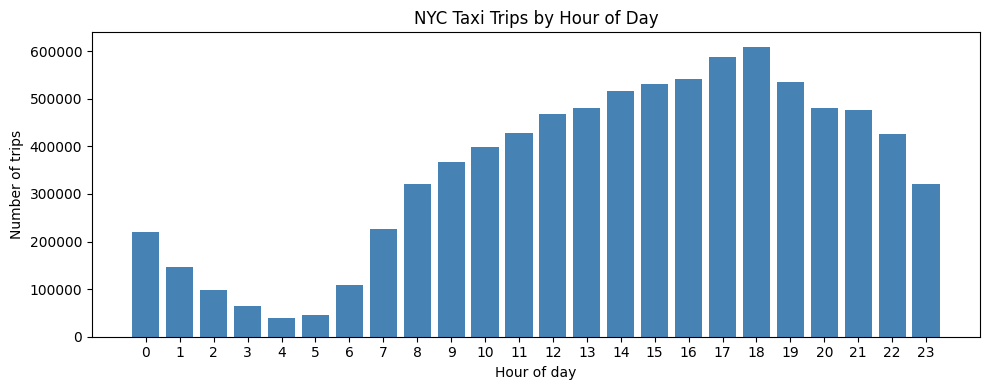

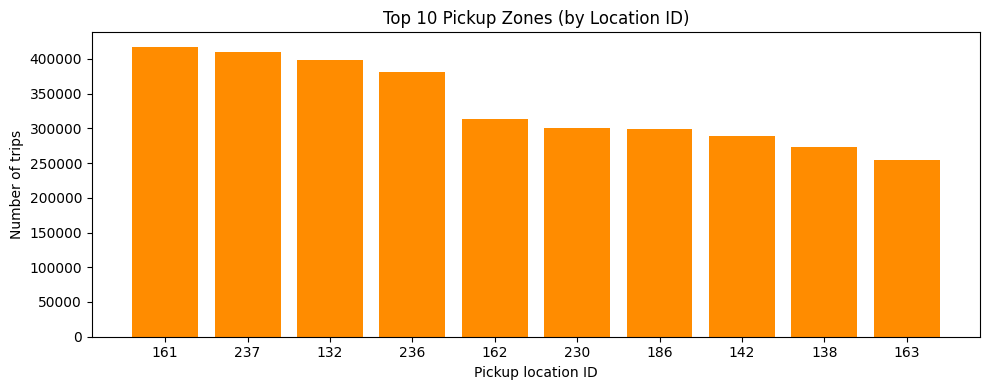

In [ ]:
# ============================================================
# PART 6: VISUALIZATION
# toPandas() brings a SMALL aggregated result to the driver.
# Never call toPandas() on the full dataset.
# ============================================================
import matplotlib.pyplot as plt

# Chart 1: trips by hour
hourly = spark.sql("""
    SELECT pickup_hour, COUNT(*) AS trips
    FROM trips GROUP BY pickup_hour ORDER BY pickup_hour
""").toPandas()

plt.figure(figsize=(10, 4))
plt.bar(hourly["pickup_hour"], hourly["trips"], color="steelblue")
plt.title("NYC Taxi Trips by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Number of trips")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("trips_by_hour.png", dpi=150)
plt.show()

# Chart 2: top 10 pickup zones
zones = spark.sql("""
    SELECT CAST(PULocationID AS STRING) AS zone, COUNT(*) AS trips
    FROM trips GROUP BY PULocationID ORDER BY trips DESC LIMIT 10
""").toPandas()

plt.figure(figsize=(10, 4))
plt.bar(zones["zone"], zones["trips"], color="darkorange")
plt.title("Top 10 Pickup Zones (by Location ID)")
plt.xlabel("Pickup location ID")
plt.ylabel("Number of trips")
plt.tight_layout()
plt.savefig("top_zones.png", dpi=150)
plt.show()

In [ ]:
# ============================================================
# PART 7: MACHINE LEARNING (Spark MLlib)
# Goal: predict fare_amount.
# duration_min is NOT used as a feature because fare is
# calculated from distance and time, which would be leakage.
# ============================================================
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

feature_cols = ["trip_distance", "pickup_hour", "pickup_dow",
                "passenger_count", "PULocationID", "DOLocationID"]

# Use a 30% sample so training finishes quickly on Colab
data = clean.sample(fraction=0.3, seed=42)

# Distributed train/test split (80/20)
train, test = data.randomSplit([0.8, 0.2], seed=42)
print("Train rows:", train.count(), "| Test rows:", test.count())

# Pipeline: step 1 packs the feature columns into one vector,
#           step 2 is the Random Forest model
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
rf = RandomForestRegressor(featuresCol="features", labelCol="fare_amount",
                           numTrees=30, maxDepth=8, seed=42)
pipeline = Pipeline(stages=[assembler, rf])

model = pipeline.fit(train)           # training runs in parallel across partitions
predictions = model.transform(test)   # predict on unseen data

predictions.select("trip_distance", "fare_amount", "prediction").show(10)

# Evaluate
for metric in ["rmse", "mae", "r2"]:
    score = RegressionEvaluator(labelCol="fare_amount",
                                predictionCol="prediction",
                                metricName=metric).evaluate(predictions)
    print(f"{metric.upper()}: {score:.3f}")

# Which features mattered most?
importances = model.stages[-1].featureImportances.toArray()
print("\nFeature importance:")
for name, imp in sorted(zip(feature_cols, importances), key=lambda x: -x[1]):
    print(f"  {name:18s} {imp:.3f}")

Train rows: 2027136 | Test rows: 507237
+-------------+-----------+------------------+
|trip_distance|fare_amount|        prediction|
+-------------+-----------+------------------+
|        18.85|       70.0| 68.53587803440448|
|        18.04|       68.1| 69.57097169472618|
|         2.57|       19.1|13.911455418936693|
|         3.55|       17.7|18.960283303671208|
|         4.19|       26.1| 21.46288381971809|
|         1.98|       12.1|12.862778285880653|
|          9.0|       40.8| 35.87698546850767|
|         5.51|       30.3|25.073198370924462|
|         0.56|        8.6|  9.45073108283906|
|         1.85|       12.8|12.241548280001627|
+-------------+-----------+------------------+
only showing top 10 rows
RMSE: 4.768
MAE: 2.848
R2: 0.916

Feature importance:
  trip_distance      0.775
  PULocationID       0.172
  DOLocationID       0.047
  pickup_hour        0.004
  passenger_count    0.002
  pickup_dow         0.001


In [ ]:
# ============================================================
# PART 8: PERFORMANCE DEMO
# Shows Spark's in-memory caching and the Catalyst optimizer.
# ============================================================
import time

def timed_query():
    """Run the same aggregation and return the time taken."""
    start = time.time()
    clean.groupBy("pickup_hour", "PULocationID").count().collect()
    return time.time() - start

# Without cache: Spark recomputes everything from the Parquet files
clean.unpersist()
t_no_cache = min(timed_query() for _ in range(2))

# With cache: Spark reads from memory
clean.cache()
clean.count()   # fills the cache
t_cache = min(timed_query() for _ in range(2))

print(f"Without cache: {t_no_cache:.2f} s")
print(f"With cache   : {t_cache:.2f} s")
print(f"Speed-up     : {t_no_cache / t_cache:.1f}x")

# Show the execution plan chosen by the Catalyst optimizer
# (screenshot this for your report)
clean.groupBy("pickup_hour").count().explain(True)

Without cache: 8.77 s
With cache   : 1.54 s
Speed-up     : 5.7x
== Parsed Logical Plan ==
'Aggregate ['pickup_hour], ['pickup_hour, 'count(1) AS count#6657]
+- Filter pickup_month#157 IN (1,2,3)
   +- Filter ((duration_min#158 > cast(1 as double)) AND (duration_min#158 < cast(180 as double)))
      +- Project [tpep_pickup_datetime#19, tpep_dropoff_datetime#20, passenger_count#21, trip_distance#22, PULocationID#23, DOLocationID#24, payment_type#25, fare_amount#26, tip_amount#27, total_amount#28, pickup_hour#155, pickup_dow#156, pickup_month#157, (cast((unix_timestamp(tpep_dropoff_datetime#20, yyyy-MM-dd HH:mm:ss, Some(Etc/UTC), true) - unix_timestamp(tpep_pickup_datetime#19, yyyy-MM-dd HH:mm:ss, Some(Etc/UTC), true)) as double) / cast(60 as double)) AS duration_min#158]
         +- Project [tpep_pickup_datetime#19, tpep_dropoff_datetime#20, passenger_count#21, trip_distance#22, PULocationID#23, DOLocationID#24, payment_type#25, fare_amount#26, tip_amount#27, total_amount#28, pickup_hour

In [ ]:
# ============================================================
# PART 9: SUMMARY NUMBERS FOR THE REPORT
# ============================================================
print("Raw rows        :", df.count())
print("Cleaned rows    :", clean.count())
print("Partitions      :", clean.rdd.getNumPartitions())
print("Rows removed (%):", round(100 * (1 - clean.count() / df.count()), 2))

Raw rows        : 9554778
Cleaned rows    : 8444455
Partitions      : 6
Rows removed (%): 11.62
